# Trabajo Final: Introducción a la Inteligencia Artificial

**Diplomatura en Inteligencia Artificial**  
Universidad Nacional de Luján (UNLu)  

**Autor:** Victor Manuel Bravo Arroyo  
**Curso:** Introducción a la Inteligencia Artificial


## 1. Introducción y Definición del Problema

## 2. Configuración del Entorno y Carga de Datos

In [119]:
import os
import urllib.request
import pandas as pd

pd.set_option('display.max_columns', None)
os.makedirs("data", exist_ok=True)

urls = {
    "data/evyth_microdatos.csv": "https://datos.yvera.gob.ar/dataset/b5819e9b-5edf-4aad-bd39-a81158a2b3f3/resource/645e5505-68ee-4cfa-90f9-fcc9a4a34a85/download/evyth_microdatos.csv",
    "data/evyth_diccionario_registro.csv": "https://datos.yvera.gob.ar/dataset/b5819e9b-5edf-4aad-bd39-a81158a2b3f3/resource/d8107236-f5ba-428d-8a31-f9b2034d8c8f/download/evyth_diccionario_registro.csv",
    "data/ipc_mensual_indec.csv": "https://apis.datos.gob.ar/series/api/series?ids=145.3_INGNACNAL_DICI_M_15&format=csv&limit=1000"
}

for path, url in urls.items():
    if not os.path.exists(path):
        print(f"Descargando {path}...")
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as response, open(path, "wb") as f_out:
            f_out.write(response.read())
        print(f"Descargado: {path}")
    else:
        print(f"Ya existe: {path}")

df_encuesta = pd.read_csv("data/evyth_microdatos.csv")
df_dicc = pd.read_csv("data/evyth_diccionario_registro.csv")
df_ipc = pd.read_csv("data/ipc_mensual_indec.csv")

print("Encuesta shape:", df_encuesta.shape)
print("Diccionario shape:", df_dicc.shape)
print("IPC shape:", df_ipc.shape)


Ya existe: data/evyth_microdatos.csv
Ya existe: data/evyth_diccionario_registro.csv
Ya existe: data/ipc_mensual_indec.csv
Encuesta shape: (490904, 88)
Diccionario shape: (480, 3)
IPC shape: (117, 29)


## 3. Análisis Exploratorio de Datos (EDA)

In [120]:
# EVyTH: Microdatos de la Encuesta de Viajes y Turismo de los Hogares (viajes, destinos, gastos y perfiles)
df_encuesta.head()


,id_hogar,id_viajes,miembro,anio,trimestre,region_origen,aglomerado_origen,region_destino,provincia_destino,localidad_destino,cod_loc_2001,codigo_2001,codigo_2010,cod_prov_2010,cod_depto_2010,cod_loc_2010,pondera,tipo_visitante,cantidad_destinos,multidestino,px06,px06_agrup,px07,px07_agrup,px08,px08_agrup,px09,px10_1,px11,px12_1,px12_2,px12_3,px12_4,px12_5,px12_6,px12_7,px12_8,px13,px14,px15_1,px15_2,px15_3,px15_4,pxb16_1_1,pxb16_1_2,pxb16_1_3,pxb16_1_4,pxb16_1_5,pxb16_1_6,pxb16_1_7,pxb16_1_9,pxb16_2,px17_1,px17_2_1,px17_2_2,px17_2_3,px17_2_4,px17_2_5,px17_2_6,px17_2_7,px17_2_8,px17_2_9,px17_2_10,px17_2_11,px17_2_12,px17_2_13,px18_1,px18_2,px18_3,px18_4,px18_5,px18_6,px18_7,gasto_pc,quintil_pcf_visitante,p002,p004,p005,p006,p006_agrup,p007,nivel_ed,cond_act,p013,j_sexo,j_edad,j_nivel_ed,j_cond_act
0,71,41201,1,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,1,1,54,4,2.0,7,1,2,1,3,4,1
1,71,41201,2,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,2,2,56,4,2.0,4,1,3,1,3,4,1
2,71,41201,3,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1
3,71,41201,4,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,1,27,2,2.0,9,1,3,1,3,4,1
4,71,61201,3,2012,1,2,33,3,6,Reta ...,819,6833070.0,6833070.0,6.0,833.0,70.0,1175.0,1,1,1,1,1,10,3.0,4,2,1,1,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1.0,9.0,9.0,9.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,6.0,100.0,10.0,9.0,10.0,10.0,8.0,700.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1


In [121]:
# Diccionario EVyTH: Mapeo de variables y codigos categoricos a sus etiquetas descriptivas
df_dicc.head(n=10)

,variable,opcion,descripcion
0,id_hogar,NaN,Código de identificación único de hogares
1,id_viajes,NaN,Código de identificación único de viajes
2,miembro,NaN,Número de miembro en el hogar
3,anio,NaN,Año
4,trimestre,NaN,Trimestre
5,region_origen,NaN,Región de residencia del hogar
6,region_origen,1.0,Ciudad de Buenos Aires
7,region_origen,2.0,Provincia de Buenos Aires - Partidos del GBA
8,region_origen,3.0,Provincia de Buenos Aires - Resto
9,region_origen,4.0,Centro


In [122]:
# IPC: Indice de Precios al Consumidor mensual INDEC (apertura por categorias, base dic-2016)
df_ipc.head()

,indice_tiempo,ipc_nivel_general_nacional,ipc_estacionales_nacional,ipc_nucleo_nacional,ipc_regulados_nacional,ipc_nivel_general_gba,ipc_estacionales_gba,ipc_nucleo_gba,ipc_regulados_gba,ipc_nivel_general_pampeana,ipc_estacionales_pampeana,ipc_nucleo_pampeana,ipc_regulados_pampeana,ipc_nivel_general_nea,ipc_estacionales_nea,ipc_nucleo_nea,ipc_regulados_nea,ipc_nivel_general_noa,ipc_estacionales_noa,ipc_nucleo_noa,ipc_regulados_noa,ipc_nivel_general_cuyo,ipc_estacionales_cuyo,ipc_nucleo_cuyo,ipc_regulados_cuyo,ipc_nivel_general_patagonia,ipc_estacionales_patagonia,ipc_nucleo_patagonia,ipc_regulados_patagonia
0,2016-12-01,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
1,2017-01-01,101.5859,101.6969,101.5039,101.8183,101.3130,101.5562,101.3389,101.1274,101.7874,102.0904,101.6093,102.2331,101.6727,102.4771,101.8639,100.3476,101.6014,101.5611,101.4339,102.2777,101.7074,100.6608,101.7235,102.2456,102.5593,100.6843,101.8374,106.1556
2,2017-02-01,103.6859,102.3345,103.2105,105.9316,103.8085,102.0783,103.2097,106.3489,103.5312,102.6254,103.1957,105.2868,103.4617,104.0713,103.4466,103.0912,103.7115,103.5611,102.9705,106.6823,103.2652,100.3694,103.1488,105.2775,104.2827,101.1740,103.5240,108.7652
3,2017-03-01,106.1476,104.7868,105.2057,110.0057,106.2627,105.8790,105.0891,109.8871,105.8173,104.1769,105.3123,108.6317,105.9880,104.9091,105.4076,109.0469,107.0550,104.2786,105.2640,115.9572,105.9238,102.0721,105.2127,110.4082,106.5167,102.5219,105.2611,113.2246
4,2017-04-01,108.9667,108.1867,107.4270,114.4649,109.0613,108.5334,107.4973,113.8991,108.6912,108.5973,107.3262,113.6053,108.3473,107.1165,107.5916,112.2076,109.9626,107.7699,107.4536,121.2229,109.4506,106.6856,107.6553,116.8444,108.6517,105.1970,107.0217,116.2906


## 4. Preprocesamiento e Ingeniería de Características

In [123]:
renombrar_columnas = {
    # 1. Identificadores y pesos
    'id_hogar': 'id_hogar',
    'id_viajes': 'id_viaje',
    'miembro': 'id_miembro',
    'pondera': 'ponderador',
    
    # 2. Fechas y Geografía
    'anio': 'anio',
    'trimestre': 'trimestre',
    'region_origen': 'region_origen',
    'aglomerado_origen': 'aglomerado_origen',
    'region_destino': 'region_destino',
    'provincia_destino': 'provincia_destino',
    'localidad_destino': 'localidad_destino',
    
    # 3. Características del Viaje
    'tipo_visitante': 'tipo_visitante',
    'cantidad_destinos': 'cantidad_destinos',
    'multidestino': 'es_multidestino',
    'px06': 'miembros_viajaron',
    'px06_agrup': 'miembros_viajaron_agrup',
    'px07': 'noches_estadia',
    'px07_agrup': 'noches_estadia_agrup',
    'px08': 'alojamiento_detallado',
    'px08_agrup': 'alojamiento',
    'px09': 'transporte',
    'px10_1': 'motivo_viaje',
    'px11': 'contrato_paquete',
    'px13': 'anticipacion_viaje',
    'px14': 'uso_internet',
    
    # 4. Actividades Turísticas (px17_2_*)
    'px17_1': 'hizo_actividades',
    'px17_2_1': 'actividad_playa',
    'px17_2_2': 'actividad_ciudad',
    'px17_2_3': 'actividad_museos_cultura',
    'px17_2_4': 'actividad_deportes',
    'px17_2_5': 'actividad_espectaculos',
    'px17_2_6': 'actividad_aventura',
    'px17_2_7': 'actividad_termas',
    'px17_2_8': 'actividad_gastronomia',
    'px17_2_9': 'actividad_compras',
    'px17_2_10': 'actividad_vida_nocturna',
    'px17_2_11': 'actividad_parques_nacionales',
    'px17_2_12': 'actividad_fiestas_populares',
    'px17_2_13': 'actividad_casino',
    
    # 5. Gasto e Ingresos
    'gasto_pc': 'gasto_pc',
    'quintil_pcf_visitante': 'quintil_ingreso',
    
    # 6. Demografía del Viajero y del Jefe de Hogar
    'p002': 'miembros_hogar',
    'p004': 'parentesco_jefe',
    'p005': 'sexo_viajero',
    'p006': 'edad_viajero',
    'p006_agrup': 'edad_viajero_agrup',
    'p007': 'asiste_educacion',
    'nivel_ed': 'nivel_educativo',
    'cond_act': 'condicion_actividad',
    'p013': 'cobertura_salud',
    'j_sexo': 'sexo_jefe',
    'j_edad': 'edad_jefe',
    'j_nivel_ed': 'nivel_educativo_jefe',
    'j_cond_act': 'condicion_actividad_jefe'
}

df_encuesta = df_encuesta.rename(columns=renombrar_columnas)
df_encuesta.head()

,id_hogar,id_viaje,id_miembro,anio,trimestre,region_origen,aglomerado_origen,region_destino,provincia_destino,localidad_destino,cod_loc_2001,codigo_2001,codigo_2010,cod_prov_2010,cod_depto_2010,cod_loc_2010,ponderador,tipo_visitante,cantidad_destinos,es_multidestino,miembros_viajaron,miembros_viajaron_agrup,noches_estadia,noches_estadia_agrup,alojamiento_detallado,alojamiento,transporte,motivo_viaje,contrato_paquete,px12_1,px12_2,px12_3,px12_4,px12_5,px12_6,px12_7,px12_8,anticipacion_viaje,uso_internet,px15_1,px15_2,px15_3,px15_4,pxb16_1_1,pxb16_1_2,pxb16_1_3,pxb16_1_4,pxb16_1_5,pxb16_1_6,pxb16_1_7,pxb16_1_9,pxb16_2,hizo_actividades,actividad_playa,actividad_ciudad,actividad_museos_cultura,actividad_deportes,actividad_espectaculos,actividad_aventura,actividad_termas,actividad_gastronomia,actividad_compras,actividad_vida_nocturna,actividad_parques_nacionales,actividad_fiestas_populares,actividad_casino,px18_1,px18_2,px18_3,px18_4,px18_5,px18_6,px18_7,gasto_pc,quintil_ingreso,miembros_hogar,parentesco_jefe,sexo_viajero,edad_viajero,edad_viajero_agrup,asiste_educacion,nivel_educativo,condicion_actividad,cobertura_salud,sexo_jefe,edad_jefe,nivel_educativo_jefe,condicion_actividad_jefe
0,71,41201,1,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,1,1,54,4,2.0,7,1,2,1,3,4,1
1,71,41201,2,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,2,2,56,4,2.0,4,1,3,1,3,4,1
2,71,41201,3,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1
3,71,41201,4,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,1,27,2,2.0,9,1,3,1,3,4,1
4,71,61201,3,2012,1,2,33,3,6,Reta ...,819,6833070.0,6833070.0,6.0,833.0,70.0,1175.0,1,1,1,1,1,10,3.0,4,2,1,1,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1.0,9.0,9.0,9.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,6.0,100.0,10.0,9.0,10.0,10.0,8.0,700.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1


In [124]:
# Cálculo del porcentaje de valores nulos por columna
porcentaje_nulos = (df_encuesta.isna().mean() * 100).round(2)

# Columnas con más del 50% de valores faltantes
nulos_criticos = porcentaje_nulos[porcentaje_nulos > 50].sort_values(ascending=False)

print(f"Total de columnas con >50% de nulos: {len(nulos_criticos)}\n")
print(nulos_criticos)

Total de columnas con >50% de nulos: 32

pxb16_1_7               99.45
pxb16_1_9               98.89
pxb16_1_6               98.25
pxb16_1_5               98.15
pxb16_1_4               96.75
pxb16_1_3               95.08
pxb16_1_2               93.32
pxb16_1_1               86.71
pxb16_2                 81.62
anticipacion_viaje      80.29
px18_4                  79.67
px18_6                  79.65
px18_1                  79.65
px18_2                  79.65
px18_5                  79.65
px18_3                  79.65
px18_7                  79.65
px12_3                  61.83
px12_4                  61.83
px12_6                  61.83
px12_1                  61.83
px12_2                  61.83
px12_7                  61.83
px12_5                  61.83
contrato_paquete        61.83
px12_8                  61.83
px15_1                  56.38
px15_3                  56.38
px15_2                  56.38
px15_4                  56.38
uso_internet            52.56
noches_estadia_agrup    50.69

In [125]:
# Eliminación de identificadores, ponderadores y variables geográficas redundantes
cols_descartar = [
    # Identificadores y ponderador muestral
    'id_hogar', 'id_viaje', 'id_miembro', 'ponderador',
    
    # Geografía redundante (nos quedamos con region_origen y region_destino)
    'localidad_destino', 'provincia_destino', 'aglomerado_origen',
    'cod_loc_2001', 'codigo_2001', 'codigo_2010', 'cod_prov_2010', 'cod_depto_2010', 'cod_loc_2010',
    
    # Redundancias (conservamos las versiones continuas y alojamiento)
    'miembros_viajaron_agrup', 'noches_estadia_agrup', 'edad_viajero_agrup', 'alojamiento_detallado',
    
    # Atributos no predictivos para gasto turístico
    'parentesco_jefe', 'asiste_educacion', 'cobertura_salud'
] + nulos_criticos.index.tolist()

df_encuesta = df_encuesta.drop(columns=cols_descartar, errors="ignore")
print("Columnas restantes:", df_encuesta.shape[1])


Columnas restantes: 37


In [126]:
# Variables binarias (Preguntas de Sí/No, sexo y actividades turísticas)
cols_binarias = [
    'tipo_visitante', 'es_multidestino', 'sexo_viajero', 'sexo_jefe', 'hizo_actividades',
    'actividad_playa', 'actividad_ciudad', 'actividad_museos_cultura', 'actividad_deportes',
    'actividad_espectaculos', 'actividad_aventura', 'actividad_termas', 'actividad_gastronomia',
    'actividad_compras', 'actividad_vida_nocturna', 'actividad_parques_nacionales',
    'actividad_fiestas_populares', 'actividad_casino'
]

# Conservar solo las que no fueron descartadas
cols_binarias = [col for col in cols_binarias if col in df_encuesta.columns]

# Mapeo: 1 -> 1 (Sí/Opción 1), todo lo demás (2: No, 9: Ns/Nr, NaN) -> 0
for col in cols_binarias:
    df_encuesta[col] = (df_encuesta[col] == 1).astype(int)

print(f"Variables binarias transformadas a 0/1: {len(cols_binarias)}")
df_encuesta[cols_binarias].head()


Variables binarias transformadas a 0/1: 18


,tipo_visitante,es_multidestino,sexo_viajero,sexo_jefe,hizo_actividades,actividad_playa,actividad_ciudad,actividad_museos_cultura,actividad_deportes,actividad_espectaculos,actividad_aventura,actividad_termas,actividad_gastronomia,actividad_compras,actividad_vida_nocturna,actividad_parques_nacionales,actividad_fiestas_populares,actividad_casino
0,1,1,1,1,1,0,0,1,0,0,0,0,0,1,0,0,1,1
1,1,1,0,1,1,0,0,1,0,0,0,0,0,1,0,0,1,1
2,1,1,0,1,1,0,0,1,0,0,0,0,0,1,0,0,1,1
3,1,1,1,1,1,0,0,1,0,0,0,0,0,1,0,0,1,1
4,1,1,0,1,1,1,0,1,0,0,0,0,0,0,0,0,0,1


In [127]:
# Mapeos de códigos numéricos a categorías textuales legibles
mapeos_categoricos = {
    'alojamiento': {
        1: 'vivienda_propia', 2: 'casa_familiares_amigos', 3: 'alquiler_temporario',
        4: 'camping', 5: 'hotel_hasta_3_estrellas', 6: 'hotel_4_o_5_estrellas', 7: 'otro'
    },
    'transporte': {
        1: 'auto_propio', 2: 'omnibus', 3: 'tren', 4: 'avion',
        5: 'embarcacion', 6: 'taxi_remis', 8: 'otro', 99: 'ns_nr'
    },
    'motivo_viaje': {
        1: 'ocio_vacaciones', 2: 'visita_familiares', 3: 'trabajo_negocios',
        4: 'estudios', 5: 'salud', 6: 'religion', 7: 'compras', 8: 'otro', 99: 'ns_nr'
    },
    'region_origen': {
        1: 'caba', 2: 'gba', 3: 'resto_pba', 4: 'centro',
        5: 'litoral', 6: 'norte', 7: 'cuyo', 8: 'patagonia'
    },
    'region_destino': {
        1: 'caba', 2: 'gba', 3: 'resto_pba', 4: 'centro',
        5: 'litoral', 6: 'norte', 7: 'cuyo', 8: 'patagonia'
    },
    'condicion_actividad': {
        1: 'ocupado', 2: 'desocupado', 3: 'inactivo', 4: 'menor_14', 9: 'ns_nr'
    },
    'condicion_actividad_jefe': {
        1: 'ocupado', 2: 'desocupado', 3: 'inactivo', 4: 'menor_14', 9: 'ns_nr'
    }
}

# Reemplazar números por sus nombres reales
for col, mapeo in mapeos_categoricos.items():
    df_encuesta[col] = df_encuesta[col].map(mapeo)

# Aplicar One-Hot Encoding
cols_nominales = list(mapeos_categoricos.keys())
df_encuesta = pd.get_dummies(df_encuesta, columns=cols_nominales, drop_first=True, dtype=int)

print("Dimensiones actuales del dataset:", df_encuesta.shape)
cols_derivadas = [col for col in df_encuesta.columns if any(col.startswith(nom + '_') for nom in cols_nominales)]
df_encuesta[cols_derivadas].head()


Dimensiones actuales del dataset: (490904, 72)


,alojamiento_camping,alojamiento_casa_familiares_amigos,alojamiento_hotel_4_o_5_estrellas,alojamiento_hotel_hasta_3_estrellas,alojamiento_otro,alojamiento_vivienda_propia,transporte_avion,transporte_embarcacion,transporte_ns_nr,transporte_omnibus,transporte_otro,transporte_taxi_remis,transporte_tren,motivo_viaje_estudios,motivo_viaje_ns_nr,motivo_viaje_ocio_vacaciones,motivo_viaje_otro,motivo_viaje_religion,motivo_viaje_salud,motivo_viaje_trabajo_negocios,motivo_viaje_visita_familiares,region_origen_centro,region_origen_cuyo,region_origen_gba,region_origen_litoral,region_origen_norte,region_origen_patagonia,region_origen_resto_pba,region_destino_centro,region_destino_cuyo,region_destino_gba,region_destino_litoral,region_destino_norte,region_destino_patagonia,region_destino_resto_pba,condicion_actividad_inactivo,condicion_actividad_menor_14,condicion_actividad_ns_nr,condicion_actividad_ocupado,condicion_actividad_jefe_inactivo,condicion_actividad_jefe_ns_nr,condicion_actividad_jefe_ocupado
0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
3,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1


In [128]:
import numpy as np

# 1. Preparar IPC a nivel trimestral (promedio de los 3 meses del trimestre)
df_ipc['indice_tiempo'] = pd.to_datetime(df_ipc['indice_tiempo'])
df_ipc['anio'] = df_ipc['indice_tiempo'].dt.year
df_ipc['trimestre'] = df_ipc['indice_tiempo'].dt.quarter

ipc_trimestral = df_ipc.groupby(['anio', 'trimestre'])['ipc_nivel_general_nacional'].mean().reset_index()

# 2. Cruce inner: conserva únicamente los viajes correspondientes al período con IPC disponible (2016-Q4 en adelante)
df_encuesta = df_encuesta.merge(ipc_trimestral, on=['anio', 'trimestre'], how='inner')

# 3. Filtrar población objetivo: turistas con estadía válida (al menos 1 noche) y gasto positivo reportado
df_encuesta = df_encuesta[(df_encuesta['noches_estadia'] > 0) & (df_encuesta['gasto_pc'] > 0)].copy()

# 4. Ajuste por inflación: gasto a precios constantes (base dic-2016 = 100)
df_encuesta['gasto_real'] = (df_encuesta['gasto_pc'] / df_encuesta['ipc_nivel_general_nacional']) * 100

# 5. Gasto diario por persona a precios constantes
df_encuesta['gasto_diario_real'] = df_encuesta['gasto_real'] / df_encuesta['noches_estadia']

# 6. Transformación logarítmica de la variable objetivo Y
df_encuesta['log_gasto_diario'] = np.log1p(df_encuesta['gasto_diario_real'])

print(f"Total de registros de turistas listos para modelar: {len(df_encuesta):,}")
df_encuesta[['anio', 'trimestre', 'noches_estadia', 'gasto_diario_real', 'log_gasto_diario']].head()


Total de registros de turistas listos para modelar: 137,678


,anio,trimestre,noches_estadia,gasto_diario_real,log_gasto_diario
6,2016,4,10,150.000000,5.017280
7,2016,4,10,150.000000,5.017280
41,2016,4,7,285.714286,5.658486
42,2016,4,7,285.714286,5.658486
43,2016,4,3,166.666667,5.121978


/media/vub/25f61be1-310a-49c4-bce7-a8bc793230e32/vub/postgrados/unlu/diplomado-ia/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/media/vub/25f61be1-310a-49c4-bce7-a8bc793230e32/vub/postgrados/unlu/diplomado-ia/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


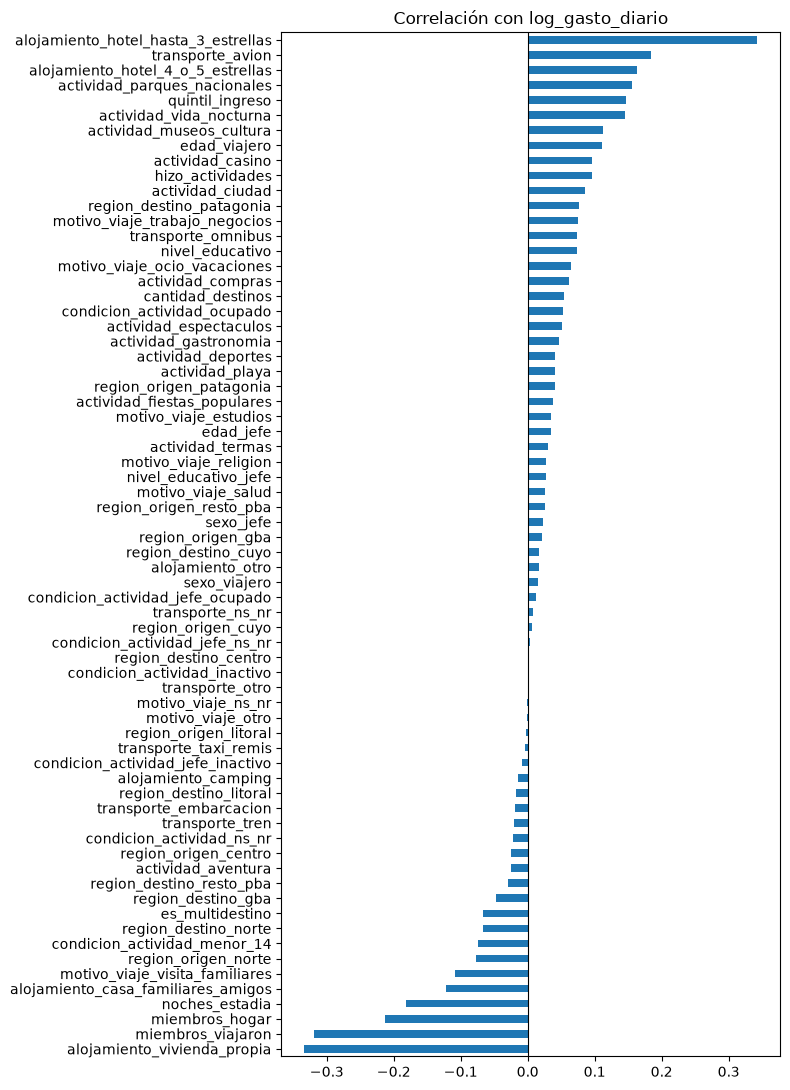

In [129]:
import matplotlib.pyplot as plt

# Excluir target, gastos intermedios y fechas
excluir = ['log_gasto_diario', 'gasto_pc', 'gasto_real', 'gasto_diario_real', 'ipc_nivel_general_nacional', 'anio', 'trimestre']

# Correlación de Pearson de cada columna contra log_gasto_diario
corrs = df_encuesta.drop(columns=excluir, errors='ignore').select_dtypes('number').corrwith(df_encuesta['log_gasto_diario']).dropna().sort_values()

# Gráfico
plt.figure(figsize=(8, 11))
corrs.plot(kind='barh')
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Correlación con log_gasto_diario")
plt.tight_layout()
plt.show()


## 5. Modelado y Entrenamiento

## 6. Evaluación de Resultados

## 7. Conclusiones